In [42]:
#PROJECT 2 — House Price Prediction System
!pip install numpy pandas matplotlib seaborn scikit-learn joblib

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [44]:
df = pd.read_csv(
    "Project_2_House_Price.csv"
)

df.head()

,House_ID,Area_sqft,Bedrooms,Location,Bathrooms,Parking,Age,Price
0,H001,2820,4,Urban,2,0,0,6530766
1,H002,3086,2,Urban,3,1,6,6647968
2,H003,2415,2,Suburban,1,0,18,4913803
3,H004,3262,2,Suburban,3,0,27,6495630
4,H005,3830,2,Urban,3,2,23,8122408


In [45]:
print("Dataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nInformation:")
df.info()

Dataset Shape:
(180, 8)

Columns:
Index(['House_ID', 'Area_sqft', 'Bedrooms', 'Location', 'Bathrooms', 'Parking',
       'Age', 'Price'],
      dtype='object')

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   House_ID   180 non-null    object
 1   Area_sqft  180 non-null    int64 
 2   Bedrooms   180 non-null    int64 
 3   Location   180 non-null    object
 4   Bathrooms  180 non-null    int64 
 5   Parking    180 non-null    int64 
 6   Age        180 non-null    int64 
 7   Price      180 non-null    int64 
dtypes: int64(6), object(2)
memory usage: 11.4+ KB


In [46]:
#Missing Values
print(
    df.isnull().sum()
)

House_ID     0
Area_sqft    0
Bedrooms     0
Location     0
Bathrooms    0
Parking      0
Age          0
Price        0
dtype: int64


In [47]:
#Remove duplicate records:
df = df.drop_duplicates()

In [48]:
#Statistical Summary
df.describe(include="all")

,House_ID,Area_sqft,Bedrooms,Location,Bathrooms,Parking,Age,Price
count,180,180.000000,180.000000,180,180.000000,180.000000,180.000000,1.800000e+02
unique,180,NaN,NaN,3,NaN,NaN,NaN,NaN
top,H001,NaN,NaN,Urban,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,78,NaN,NaN,NaN,NaN
mean,NaN,2232.088889,2.972222,NaN,2.583333,0.905556,14.988889,5.076873e+06
std,NaN,975.741353,1.400042,NaN,1.107995,0.823518,9.034996,1.768010e+06
min,NaN,611.000000,1.000000,NaN,1.000000,0.000000,0.000000,2.160411e+06
25%,NaN,1394.250000,2.000000,NaN,2.000000,0.000000,7.000000,3.437138e+06
50%,NaN,2170.000000,3.000000,NaN,3.000000,1.000000,14.000000,4.986793e+06
75%,NaN,3104.000000,4.000000,NaN,4.000000,2.000000,23.250000,6.443211e+06


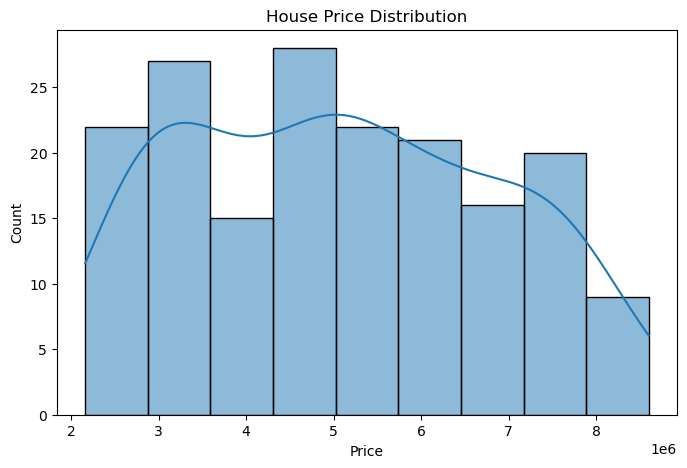

In [49]:
'''Visualization
House Price Distribution'''
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Price"],
    kde=True
)

plt.title(
    "House Price Distribution"
)

plt.xlabel("Price")

plt.show()

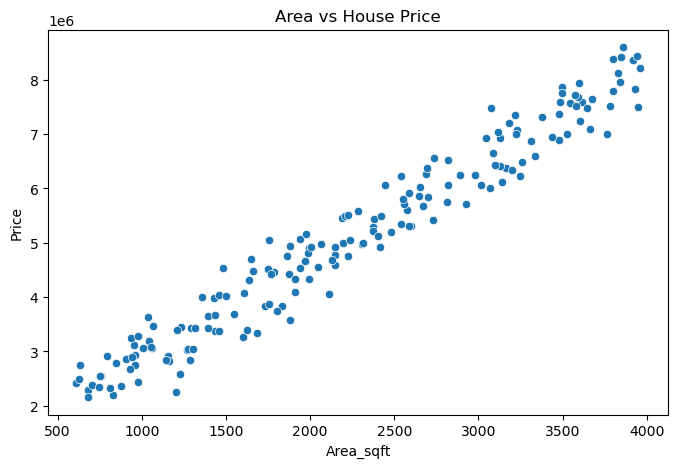

In [50]:
#Area vs Price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Area_sqft",
    y="Price"
)

plt.title(
    "Area vs House Price"
)

plt.show()

In [51]:
#Features and Target
X = df[
    [
        "Area_sqft",
        "Bedrooms",
        "Location",
        "Bathrooms",
        "Parking",
        "Age"
    ]
]

y = df["Price"]


In [52]:
'''Identify Numerical and Categorical Features

Numerical features'''
numeric_features = [
    "Area_sqft",
    "Bedrooms",
    "Bathrooms",
    "Parking",
    "Age"
]
#Categorical feature
categorical_features = [
    "Location"
]


In [53]:
#Preprocessing Pipeline
numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

#Categorical pipeline
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])
#Combine both
preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

In [54]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(
    "Training data:",
    X_train.shape
)

print(
    "Testing data:",
    X_test.shape
)

Training data: (144, 6)
Testing data: (36, 6)


In [55]:
#Algorithm 1: Linear Regression
linear_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    
    (
        "model",
        LinearRegression()
    )
])
#Train
linear_model.fit(
    X_train,
    y_train
)
#Prediction
linear_prediction = linear_model.predict(
    X_test
)

In [56]:
#Evaluate Linear Regression
mae_linear = mean_absolute_error(
    y_test,
    linear_prediction
)

rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        linear_prediction
    )
)

r2_linear = r2_score(
    y_test,
    linear_prediction
)

print(
    "Linear Regression"
)

print(
    "MAE:",
    mae_linear
)

print(
    "RMSE:",
    rmse_linear
)

print(
    "R2:",
    r2_linear
)

Linear Regression
MAE: 111861.96910827864
RMSE: 135418.9960922881
R2: 0.9951960107546259


In [57]:
#Algorithm 2: Random Forest
rf_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    
    (
        "model",
        RandomForestRegressor(
            n_estimators=100,
            random_state=42
        )
    )
])
#Train
rf_model.fit(
    X_train,
    y_train
)
#Prediction
rf_prediction = rf_model.predict(
    X_test
)

In [58]:
#Evaluate Random Forest
mae_rf = mean_absolute_error(
    y_test,
    rf_prediction
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        rf_prediction
    )
)

r2_rf = r2_score(
    y_test,
    rf_prediction
)

print(
    "Random Forest Regression"
)

print(
    "MAE:",
    mae_rf
)

print(
    "RMSE:",
    rmse_rf
)

print(
    "R2:",
    r2_rf
)

Random Forest Regression
MAE: 211518.9486111111
RMSE: 270318.82550468756
R2: 0.9808576421674691


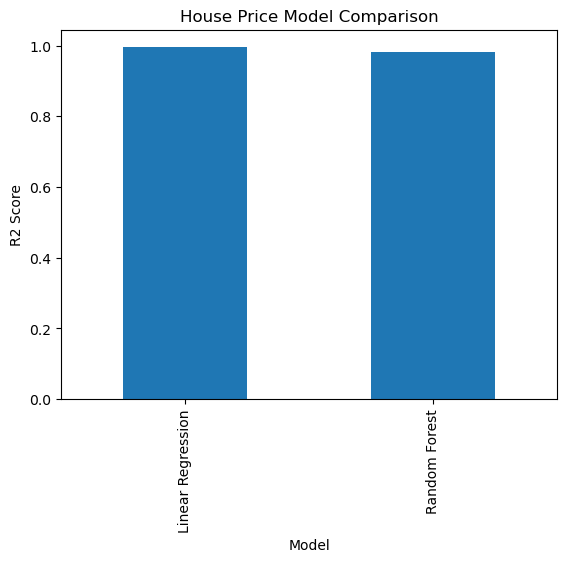

In [59]:
#Compare Both Models
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    
    "MAE": [
        mae_linear,
        mae_rf
    ],
    
    "RMSE": [
        rmse_linear,
        rmse_rf
    ],
    
    "R2": [
        r2_linear,
        r2_rf
    ]
})

comparison

#Graph
comparison.plot(
    x="Model",
    y="R2",
    kind="bar",
    legend=False
)

plt.title(
    "House Price Model Comparison"
)

plt.ylabel(
    "R2 Score"
)

plt.show()

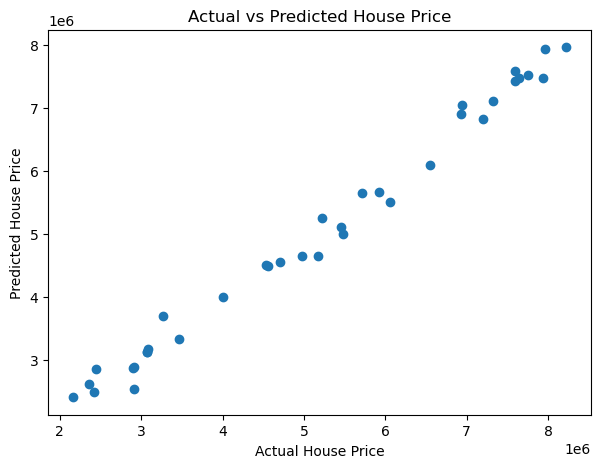

In [60]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    rf_prediction
)

plt.xlabel(
    "Actual House Price"
)

plt.ylabel(
    "Predicted House Price"
)

plt.title(
    "Actual vs Predicted House Price"
)

plt.show()

In [61]:
#Predict New House Price
new_house = pd.DataFrame({
    "Area_sqft": [1800],
    "Bedrooms": [3],
    "Location": ["Urban"],
    "Bathrooms": [2],
    "Parking": [1],
    "Age": [5]
})

#Prediction
predicted_price = rf_model.predict(
    new_house
)

print(
    "Predicted House Price:",
    round(
        float(predicted_price[0]),
        2
    )
)

Predicted House Price: 4528893.7


In [62]:
joblib.dump(
    rf_model,
    "house_price_model.pkl"
)

print(
    "House price model saved successfully!"
)

House price model saved successfully!
